In [2]:
import collections
import math
import os
import re
import time
import warnings

import alignparse
import alignparse.ccs
from alignparse.constants import CBPALETTE
import alignparse.minimap2
import alignparse.targets

import dms_variants
import dms_variants.plotnine_themes
import dms_variants.utils

from IPython.display import display, HTML

import numpy

import pandas as pd

from plotnine import *

import yaml

In [3]:
theme_set(dms_variants.plotnine_themes.theme_graygrid())

In [4]:
print(f"Using alignparse version {alignparse.__version__}")
print(f"Using dms_variants version {dms_variants.__version__}")

Using alignparse version 0.6.2
Using dms_variants version 1.6.0


In [5]:
warnings.simplefilter('ignore')

In [6]:
with open('config.yaml') as f:
    config = yaml.safe_load(f)

In [7]:
os.makedirs(config['figs_dir'], exist_ok=True)
os.makedirs(config['process_ccs_dir'], exist_ok=True)

In [8]:
background = "aLIHA"

In [9]:
pacbio_runs = (
    pd.read_csv(config['pacbio_runs'], dtype=str)
    .drop(columns=['ccs'])
    .assign(name=lambda x: x['library'] + '_' + x['bg'] + '_' + x['run'],
            fastq=lambda x: config['ccs_dir'] + '/' + x['name'] + '_ccs.fastq.gz'
            )
    )
 
pacbio_runs.drop(pacbio_runs[pacbio_runs['bg'] != background].index,inplace=True)

display(HTML(pacbio_runs.to_html(index=False)))

library,bg,run,name,fastq
pool1,aLIHA,214227_A,pool1_aLIHA_214227_A,results/ccs/pool1_aLIHA_214227_A_ccs.fastq.gz
pool2,aLIHA,214227_A,pool2_aLIHA_214227_A,results/ccs/pool2_aLIHA_214227_A_ccs.fastq.gz


In [10]:
print(f"Reading amplicons from {config['amplicons_' + background]}")
print(f"Reading feature parse specs from {config['feature_parse_specs_' + background]}")

targets = alignparse.targets.Targets(
                seqsfile=config['amplicons_' + background],
                feature_parse_specs=config['feature_parse_specs_' + background])

Reading amplicons from data/PacBio_amplicon_aLIHA.gb
Reading feature parse specs from data/feature_parse_specs_aLIHA.yaml


In [11]:
background = "aLIHA"

In [12]:
print(f"Reading amplicons from {config['amplicons_' + background]}")
print(f"Reading feature parse specs from {config['feature_parse_specs_' + background]}")

targets = alignparse.targets.Targets(
                seqsfile=config['amplicons_' + background],
                feature_parse_specs=config['feature_parse_specs_' + background])

Reading amplicons from data/PacBio_amplicon_aLIHA.gb
Reading feature parse specs from data/feature_parse_specs_aLIHA.yaml


In [13]:
with open('config.yaml') as f:
    config = yaml.safe_load(f)

In [14]:
background = "aLIHA"

In [15]:
print(f"Reading amplicons from {config['amplicons_' + background]}")
print(f"Reading feature parse specs from {config['feature_parse_specs_' + background]}")

targets = alignparse.targets.Targets(
                seqsfile=config['amplicons_' + background],
                feature_parse_specs=config['feature_parse_specs_' + background])

Reading amplicons from data/PacBio_amplicon_aLIHA.gb
Reading feature parse specs from data/feature_parse_specs_aLIHA.yaml


Saving plot to results/process_ccs/amplicons_aLIHA.pdf


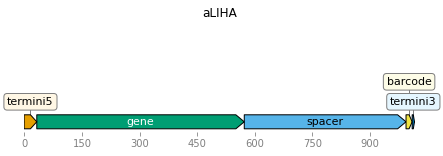

In [16]:
fig = targets.plot(ax_width=7,
                   plots_indexing='biopython',  # numbering starts at 0
                   ax_height=2,  # height of each plot
                   hspace=1.2,  # vertical space between plots
                   )

plotfile = os.path.join(config['process_ccs_dir'], 'amplicons_'+background+'.pdf')
print(f"Saving plot to {plotfile}")
fig.savefig(plotfile, bbox_inches='tight')

In [17]:
print(targets.feature_parse_specs('yaml'))

aLIHA:
  query_clip5: 4
  query_clip3: 4
  termini5:
    filter:
      clip5: 4
      mutation_nt_count: 1
      mutation_op_count: null
      clip3: 0
    return: []
  gene:
    filter:
      mutation_nt_count: 90
      mutation_op_count: null
      clip5: 0
      clip3: 0
    return:
    - mutations
    - accuracy
  spacer:
    filter:
      mutation_nt_count: 1
      mutation_op_count: null
      clip5: 0
      clip3: 0
    return: []
  barcode:
    filter:
      mutation_nt_count: 0
      mutation_op_count: null
      clip5: 0
      clip3: 0
    return:
    - sequence
    - accuracy
  termini3:
    filter:
      clip3: 4
      mutation_nt_count: 1
      mutation_op_count: null
      clip5: 0
    return: []



In [18]:
mapper = alignparse.minimap2.Mapper(alignparse.minimap2.OPTIONS_CODON_DMS)

print(f"Using `minimap2` {mapper.version} with these options:\n" +
      ' '.join(mapper.options))

Using `minimap2` 2.17-r941 with these options:
-A2 -B4 -O12 -E2 --end-bonus=13 --secondary=no --cs


In [19]:
readstats, aligned, filtered = targets.align_and_parse(
        df=pacbio_runs,
        mapper=mapper,
        outdir=config['process_ccs_dir'],
        name_col='run',
        group_cols=['name', 'library'],
        queryfile_col='fastq',
        overwrite=True,
        ncpus=config['max_cpus'],
        )

In [20]:
readstats = (
    readstats
    .assign(category_all_targets=lambda x: x['category'].str.split().str[0],
            target=lambda x: x['category'].str.split(None, n=1).str[1],
            valid=lambda x: x['category_all_targets'] == 'aligned')
    )

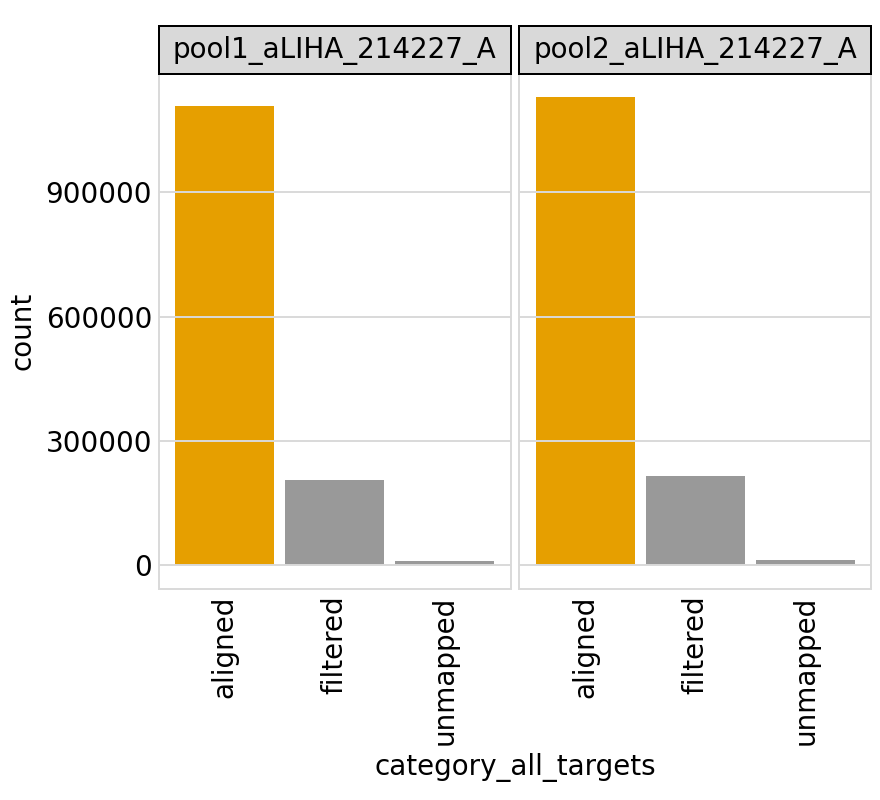

In [132]:
ncol = 2
p = (
    ggplot(readstats
           .groupby(['name', 'category_all_targets', 'valid'])
           .aggregate({'count': 'sum'})
           .reset_index(),
           aes('category_all_targets', 'count', fill='valid')) +
    geom_bar(stat='identity') +
    facet_wrap('~ name', ncol=ncol) +
    theme(axis_text_x=element_text(angle=90),
          figure_size=(2.2 * min(ncol, len(pacbio_runs)),
                       4 * math.ceil(len(pacbio_runs) / ncol)),
          panel_grid_major_x=element_blank(),
          legend_position='none',
          ) +
    scale_fill_manual(values=CBPALETTE)
    )
p.draw()

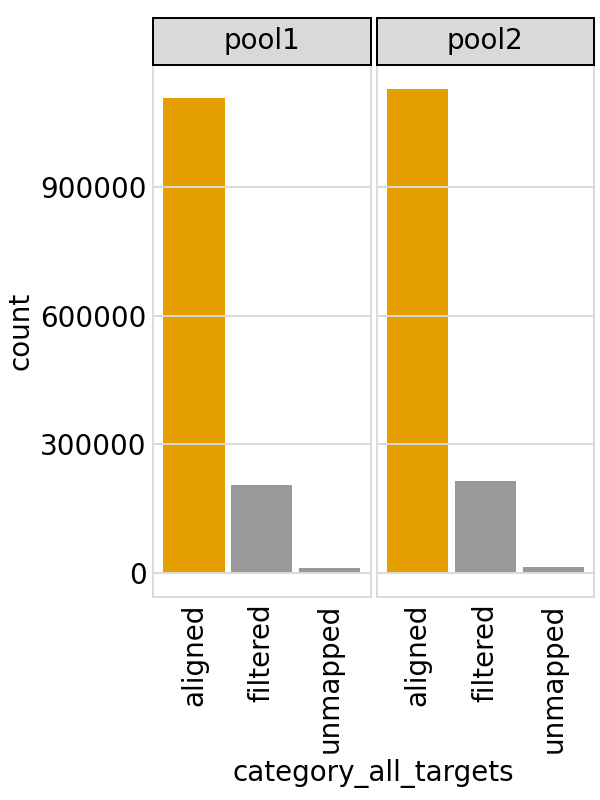

In [129]:
p = (
    ggplot(readstats
           .groupby(['library', 'category_all_targets', 'valid'])
           .aggregate({'count': 'sum'})
           .reset_index(), 
           aes('category_all_targets', 'count', fill='valid')) +
    geom_bar(stat='identity') +
    facet_wrap('~ library', nrow=1) +
    theme(axis_text_x=element_text(angle=90),
          figure_size=(1.5 * pacbio_runs['library'].nunique(), 4),
          panel_grid_major_x=element_blank(),
          legend_position='none',
          ) +
    scale_fill_manual(values=CBPALETTE)
    )
p.draw()
     


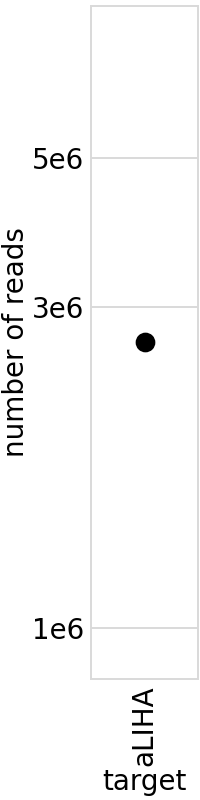

In [128]:
p = (
    ggplot(readstats
           .groupby(['target'])
           .aggregate({'count': 'sum'})
           .reset_index(), 
           aes('target', 'count')) +
    geom_point(stat='identity', size=3) +
    theme(axis_text_x=element_text(angle=90),
          figure_size=(1 * readstats['target'].nunique(), 4),
          panel_grid_major_x=element_blank(),
          ) +
    scale_y_log10(name='number of reads')
    )
p.draw()

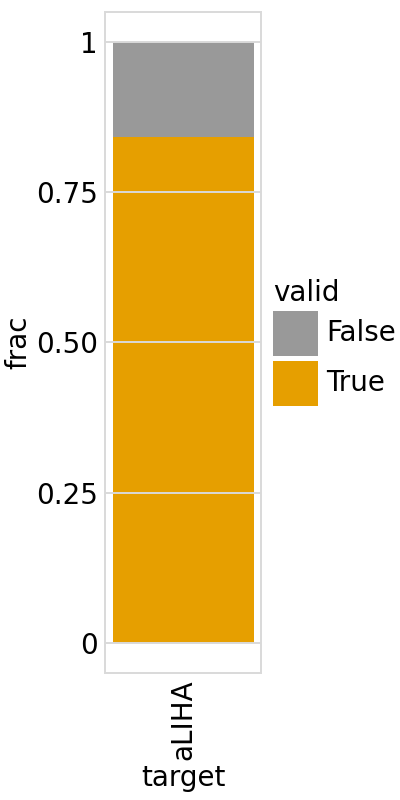

In [124]:
p = (
    ggplot(readstats
           .groupby(['target', 'valid'])
           .aggregate({'count': 'sum'})
           .reset_index()
           .assign(total=lambda x: x.groupby('target')['count'].transform('sum'),
                   frac=lambda x: x['count'] / x['total'],
                   ), 
           aes('target', 'frac', fill='valid')) +
    geom_bar(stat='identity') +
    theme(axis_text_x=element_text(angle=90),
          figure_size=(2 * readstats['target'].nunique(), 4),
          panel_grid_major_x=element_blank(),
          ) +
    scale_fill_manual(values=CBPALETTE)
    )
p.draw()

In [25]:
other_cutoff = 0.02  # group as "other" reasons with <= this frac

filtered_df = (
    pd.concat(df.assign(target=target) for target, df in filtered.items())
    .groupby(['library', 'name', 'run', 'filter_reason'])
    .size()
    .rename('count')
    .reset_index()
    .assign(tot_reason_frac=lambda x: (x.groupby('filter_reason')['count']
                                       .transform('sum')) / x['count'].sum(),
            filter_reason=lambda x: numpy.where(x['tot_reason_frac'] > other_cutoff,
                                                x['filter_reason'],
                                                'other')
            )
    )
     

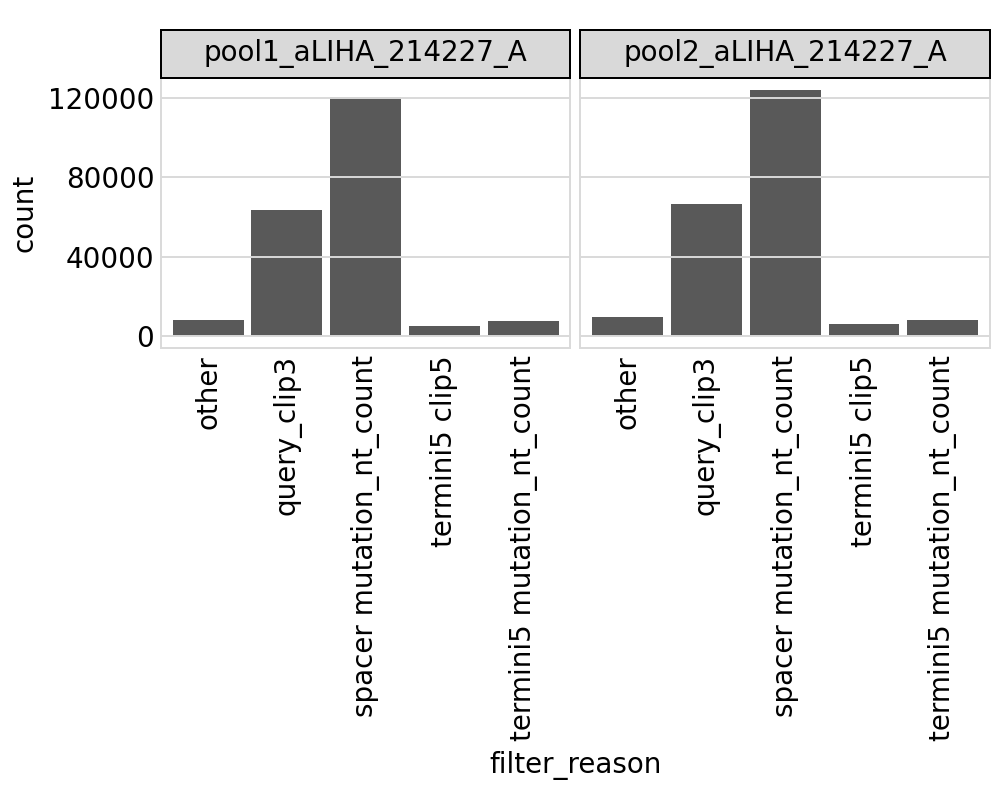

In [117]:
ncol = 7
nreasons = filtered_df['filter_reason'].nunique()

p = (
    ggplot(filtered_df, aes('filter_reason', 'count')) +
    geom_bar(stat='identity') +
    facet_wrap('~ name', ncol=ncol) +
    theme(axis_text_x=element_text(angle=90),
          figure_size=(0.5 * nreasons * min(ncol, len(pacbio_runs)),
                       4 * math.ceil(len(pacbio_runs) / ncol)),
          panel_grid_major_x=element_blank(),
          )
    )
p.draw()
     

In [27]:
aligned_df = (
    pd.concat(df.assign(target=target) for target, df in aligned.items())
    .drop(columns=['query_clip5', 'query_clip3', 'run','name'])
    .rename(columns={'barcode_sequence': 'barcode'})
    )

print(f"First few lines of information on the parsed alignments:")
display(HTML(aligned_df.head().to_html(index=False)))

First few lines of information on the parsed alignments:


library,query_name,gene_mutations,gene_accuracy,barcode,barcode_accuracy,target
pool1,m64272e_240321_215736/6/ccs,,1.000000,ACTCCCCCGGCAAAGG,0.998024,aLIHA
pool1,m64272e_240321_215736/55/ccs,,0.999894,TCGCCGTCAACACTAA,1.000000,aLIHA
pool1,m64272e_240321_215736/64/ccs,,1.000000,GCGCCCGTGTTCATAT,1.000000,aLIHA
pool1,m64272e_240321_215736/69/ccs,T514G T515G ins536C,0.999996,CGTCCCCCATCGCCCT,1.000000,aLIHA
pool1,m64272e_240321_215736/85/ccs,G307T A309T A341G G342T del479to479 del485to485 G486A del493to493,1.000000,ATAGTAACGTTACCAC,1.000000,aLIHA


In [28]:
aligned_df.to_csv(config['processed_ccs_file' + '_' + background], index=False)

print("Barcodes and mutations for valid processed CCSs "
      f"have been written to {config['processed_ccs_file' + '_' + background]}.")

Barcodes and mutations for valid processed CCSs have been written to results/process_ccs/processed_ccs_aLIHA.csv.


In [29]:
os.makedirs(config['variants_dir'], exist_ok=True)
os.makedirs(config['figs_dir'], exist_ok=True)

In [30]:
processed_ccs = pd.read_csv(config['processed_ccs_file' + '_' + background], na_filter=None)

nlibs = processed_ccs['library'].nunique()  # number of unique libraries

ntargets = processed_ccs['target'].nunique()  # number of unique targets

print(f"Read {len(processed_ccs)} CCSs from {nlibs} libraries and {ntargets} targets.")

display(HTML(processed_ccs.head().to_html(index=False)))

Read 2235417 CCSs from 2 libraries and 1 targets.


library,query_name,gene_mutations,gene_accuracy,barcode,barcode_accuracy,target
pool1,m64272e_240321_215736/6/ccs,,1.000000,ACTCCCCCGGCAAAGG,0.998024,aLIHA
pool1,m64272e_240321_215736/55/ccs,,0.999894,TCGCCGTCAACACTAA,1.000000,aLIHA
pool1,m64272e_240321_215736/64/ccs,,1.000000,GCGCCCGTGTTCATAT,1.000000,aLIHA
pool1,m64272e_240321_215736/69/ccs,T514G T515G ins536C,0.999996,CGTCCCCCATCGCCCT,1.000000,aLIHA
pool1,m64272e_240321_215736/85/ccs,G307T A309T A341G G342T del479to479 del485to485 G486A del493to493,1.000000,ATAGTAACGTTACCAC,1.000000,aLIHA


In [31]:
display(HTML(
    processed_ccs
    .groupby(['target', 'library'])
    .aggregate(total_CCSs=('barcode', 'size'),
               unique_barcodes=('barcode', 'nunique'))
    .assign(avg_CCSs_per_barcode=lambda x: x['total_CCSs'] / x['unique_barcodes'])
    .round(2)
    .to_html()
    ))

In [32]:
error_rate_floor = 1e-7  # error rates < this set to this
if error_rate_floor >= config['max_error_rate']:
    raise ValueError('error_rate_floor must be < max_error_rate')

processed_ccs = (
    processed_ccs
    .assign(barcode_error=lambda x: numpy.clip(1 - x['barcode_accuracy'],
                                               error_rate_floor, None),
            gene_error=lambda x: numpy.clip(1 - x['gene_accuracy'],
                                            error_rate_floor, None)
            )
    )

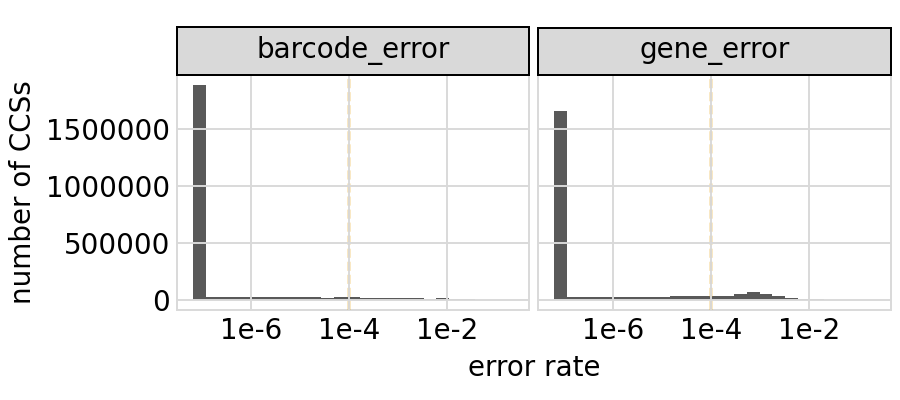

In [33]:
_ = (
 ggplot(processed_ccs
        .melt(value_vars=['barcode_error', 'gene_error'],
              var_name='feature_type', value_name='error rate'),
        aes('error rate')) +
 geom_histogram(bins=25) +
 geom_vline(xintercept=config['max_error_rate'],
            linetype='dashed',
            color=CBPALETTE[1]) +
 facet_wrap('~ feature_type') +
 theme(figure_size=(4.5, 2)) +
 ylab('number of CCSs') +
 scale_x_log10()
 )
_.draw()

In [34]:
processed_ccs = (
    processed_ccs
    .assign(retained=lambda x: ((x['gene_error'] < config['max_error_rate']) &
                                (x['barcode_error'] < config['max_error_rate'])))
    )
     

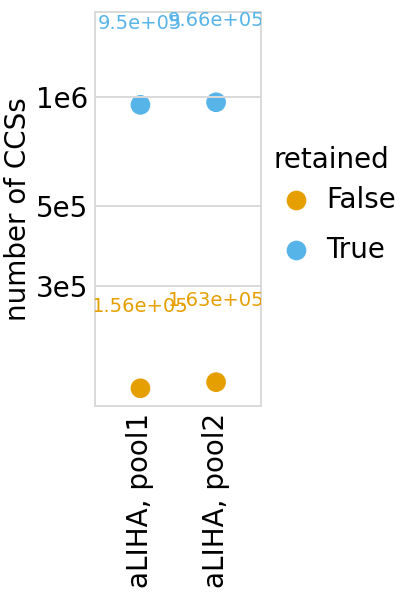

In [35]:
_ = (
 ggplot(processed_ccs.assign(xlabel=lambda x: x['target'] + ', ' + x['library'])
                     .groupby(['xlabel', 'retained'])
                     .size()
                     .rename('count')
                     .reset_index(),
        aes('xlabel', 'count', color='retained', label='count')) +
 geom_point(size=3) +
 geom_text(va='bottom', size=7, ha='center',format_string='{:.3g}', nudge_y=0.2) +
 theme(figure_size=(1 * nlibs * ntargets, 3),
       panel_grid_major_x=element_blank(),
       axis_text_x=element_text(angle=90),
       ) +
 scale_y_log10(name='number of CCSs') +
 xlab('') +
 scale_color_manual(values=CBPALETTE[1:])
)
_.draw()

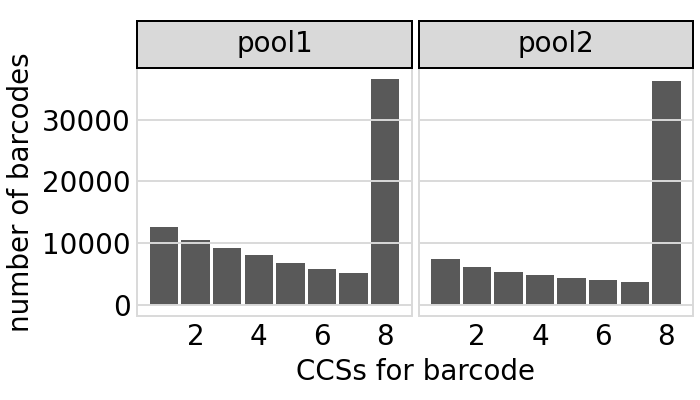

In [36]:
max_count = 8 # in plot, group all barcodes with >= this many counts

p = (
 ggplot(
    processed_ccs
     .query('retained')
     .groupby(['library', 'barcode'])
     .size()
     .rename('nseqs')
     .reset_index()
     .assign(nseqs=lambda x: numpy.clip(x['nseqs'], None, max_count)),
    aes('nseqs')) +
 geom_bar() +
 facet_wrap('~ library', nrow=1) +
 theme(figure_size=(1.75 * nlibs, 2),
       panel_grid_major_x=element_blank(),
       ) +
 ylab('number of barcodes') +
 xlab('CCSs for barcode')
 )

p.draw()

In [37]:
processed_ccs = processed_ccs.reset_index(drop=True)

processed_ccs = alignparse.consensus.add_mut_info_cols(processed_ccs,
                                                       mutation_col='gene_mutations',
                                                       n_indel_col='n_indels')

processed_ccs = processed_ccs.assign(has_indel=lambda x: x['n_indels'] > 0)

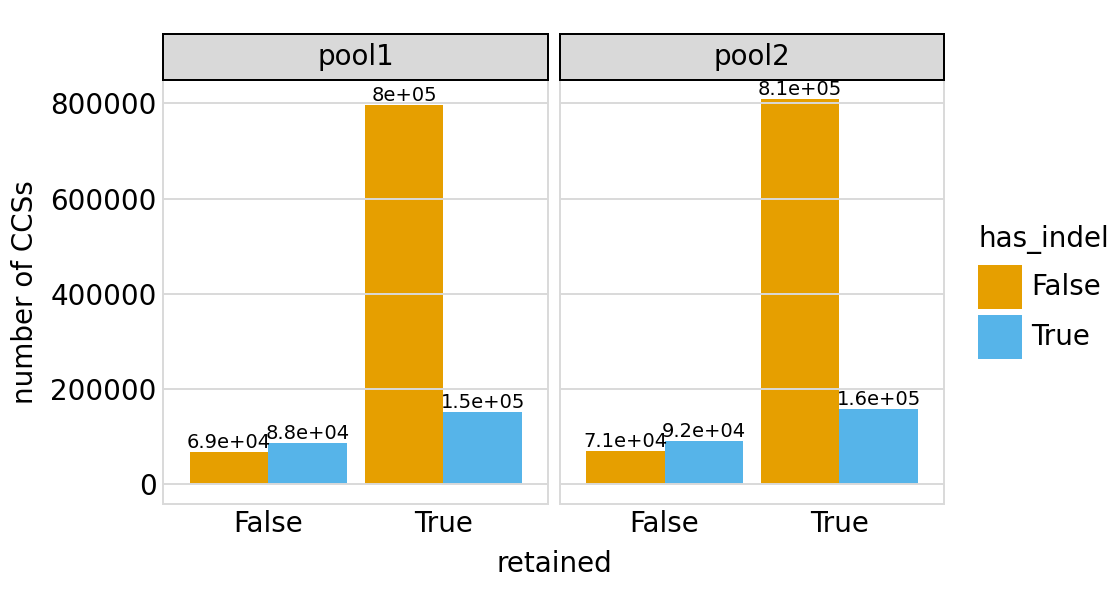

In [133]:
_ = (
 ggplot(processed_ccs,
        aes('retained', fill='has_indel')) +
 geom_bar(position='dodge') +
 geom_text(aes(label='..count..'), stat='count', va='bottom', size=7,
           position=position_dodge(width=0.9), format_string='{:.2g}') +
 theme(figure_size=(2.8 * nlibs, 3),
       panel_grid_major_x=element_blank(),
       ) +
 ylab('number of CCSs') +
 scale_fill_manual(values=CBPALETTE[1:]) +
 facet_wrap('~ library', nrow=1)
 )
_.draw()

In [39]:
high_acc = config['max_error_rate'] / 10
empirical_acc = []

for desc, query_str in [
        ('retained', 'retained'),
        ('retained, no indel', 'retained and not has_indel'),
        ('10X accuracy',
         f"(gene_error < {high_acc}) and (barcode_error < {high_acc})"),
        ('10X accuracy, no indel',
         f"(gene_error < {high_acc}) and (barcode_error < {high_acc}) and not has_indel")
        ]:
    # get just CCSs in that category
    df = processed_ccs.query(query_str)
    
    # compute empirical accuracy
    empirical_acc.append(
        alignparse.consensus.empirical_accuracy(df,
                                                mutation_col='gene_mutations')
        .assign(description=desc)
        .merge(df
               .groupby('library')
               .size()
               .rename('number_CCSs')
               .reset_index()
               )
        )

# make description categorical to preserve order, and annotate as "actual"
# the category ("retained, no indel") that we will use for building variants.
empirical_acc = (
    pd.concat(empirical_acc, ignore_index=True, sort=False)
    .assign(description=lambda x: pd.Categorical(x['description'],
                                                 x['description'].unique(),
                                                 ordered=True),
            actual=lambda x: numpy.where(x['description'] == 'retained, no indel',
                                         True, False),
            )
    )
     

In [40]:
display(HTML(empirical_acc.to_html(index=False)))

library,accuracy,description,number_CCSs,actual
pool1,0.981372,retained,950221,False
pool2,0.981217,retained,966086,False
pool1,0.997231,"retained, no indel",797322,True
pool2,0.997123,"retained, no indel",808213,True
pool1,0.987682,10X accuracy,893026,False
pool2,0.987793,10X accuracy,907521,False
pool1,0.997224,"10X accuracy, no indel",754255,False
pool2,0.997153,"10X accuracy, no indel",764320,False


Saving plot to results/figures/empirical_CCS_accuracy.pdf


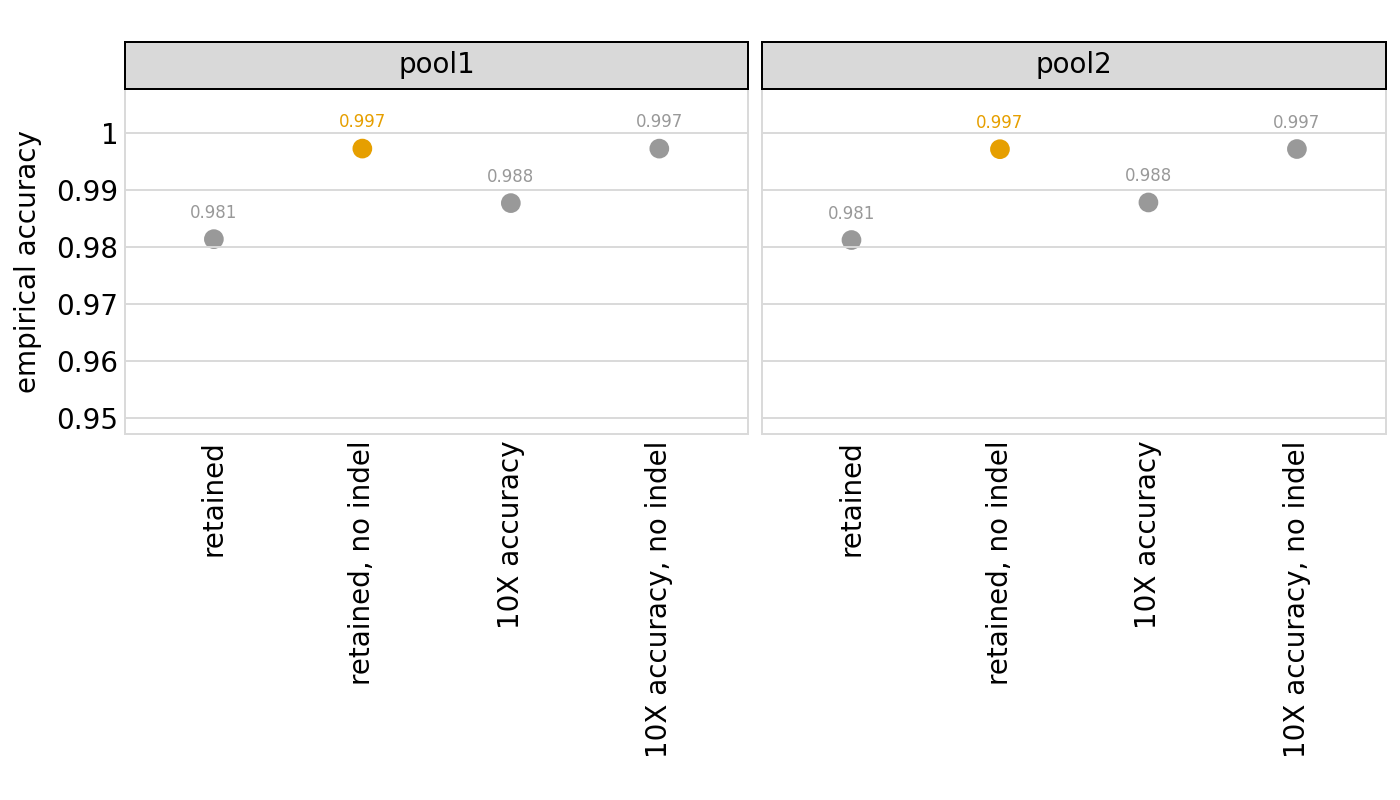

In [112]:
p = (
    ggplot(empirical_acc,
           aes('description', 'accuracy', color='actual', label='accuracy')
           ) +
    geom_point(size=3) +
    geom_text(va='bottom', size=6, format_string='{:.3g}', nudge_y=0.003) +
    facet_wrap('~ library', ncol=8) +
    theme(figure_size=(3.5 * nlibs, 4),
          axis_text_x=element_text(angle=90),
          panel_grid_major_x=element_blank(),
          ) +
    xlab('') +
    scale_y_continuous(name='empirical accuracy', limits=(0.95, 1.005)) +
    scale_color_manual(values=CBPALETTE, guide=False)
    )

plotfile = os.path.join(config['figs_dir'], 'empirical_CCS_accuracy.pdf')
print(f"Saving plot to {plotfile}")
p.draw()

In [42]:
consensus, dropped = alignparse.consensus.simple_mutconsensus(
                        processed_ccs.query('retained'),
                        group_cols=('library', 'barcode', 'target'),
                        mutation_col='gene_mutations',
                        )

In [43]:
display(HTML(consensus.head().to_html(index=False)))

library,barcode,target,gene_mutations,variant_call_support
pool1,AAAAAAAAAGAACTAG,aLIHA,A457T A458G G459T,25
pool1,AAAAAAAAGATCTAGG,aLIHA,C411A,8
pool1,AAAAAAACCAACCCTT,aLIHA,C269T C270T,33
pool1,AAAAAAACCCCAAAAT,aLIHA,G247A G248T C249T,11
pool1,AAAAAAAGCAGGACCC,aLIHA,A331T C332T A333G,5


In [44]:
consensus = alignparse.consensus.add_mut_info_cols(
                    consensus,
                    mutation_col='gene_mutations',
                    sub_str_col='substitutions',
                    n_indel_col='number_of_indels',
                    overwrite_cols=True)

display(HTML(consensus.head().to_html(index=False)))

library,barcode,target,gene_mutations,variant_call_support,substitutions,number_of_indels
pool1,AAAAAAAAAGAACTAG,aLIHA,A457T A458G G459T,25,A457T A458G G459T,0
pool1,AAAAAAAAGATCTAGG,aLIHA,C411A,8,C411A,0
pool1,AAAAAAACCAACCCTT,aLIHA,C269T C270T,33,C269T C270T,0
pool1,AAAAAAACCCCAAAAT,aLIHA,G247A G248T C249T,11,G247A G248T C249T,0
pool1,AAAAAAAGCAGGACCC,aLIHA,A331T C332T A333G,5,A331T C332T A333G,0


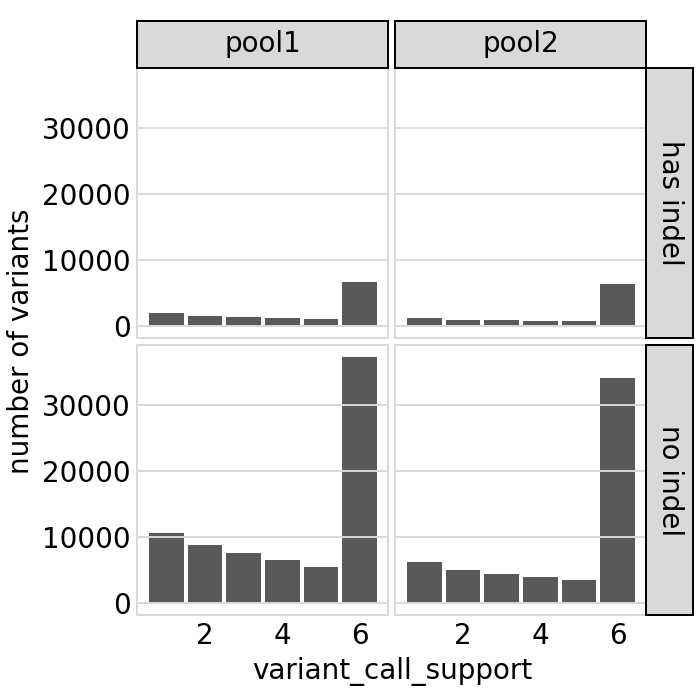

In [45]:
max_variant_call_support = 6  # group variants with >= this much support

_ = (
 ggplot(consensus
        .assign(variant_call_support=lambda x: numpy.clip(x['variant_call_support'],
                                                          None,
                                                          max_variant_call_support),
                indel_state=lambda x: numpy.where(x['number_of_indels'] > 0,
                                                  'has indel', 'no indel')
                ),
        aes('variant_call_support')) +
 geom_bar() +
 ylab('number of variants') +
 facet_grid('indel_state ~ library') +
 theme(figure_size=(1.75 * nlibs, 3.5),
       panel_grid_major_x=element_blank(),
       ) 
 )
_.draw()

library,target,consensus sequences
pool1,aLIHA,76345
pool2,aLIHA,57489


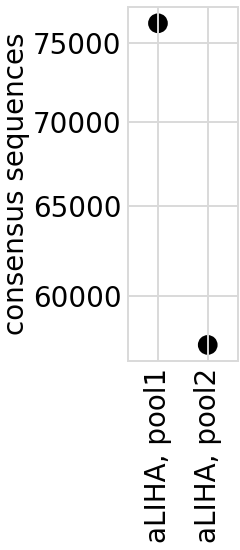

In [114]:
consensus = consensus.query('number_of_indels == 0')

lib_target_counts = (
    consensus
    .groupby(['library', 'target'])
    .size()
    .rename('consensus sequences')
    .reset_index()
    )

display(HTML(lib_target_counts.to_html(index=False)))

p = (ggplot(lib_target_counts.assign(xlabel=lambda x: x['target'] + ', ' + x['library']),
            aes('xlabel', 'consensus sequences')) +
     geom_point(size=3) +
     theme(figure_size=(0.6 * nlibs * ntargets, 2.75),
           axis_text_x=element_text(angle=90)) +
     xlab('') +
     scale_y_log10()
     )

p.draw()

In [47]:
print(f"Writing nucleotide variants to {config['nt_variant_table_file' + '_' + background]}")
      
(consensus
 [['target', 'library', 'barcode', 'substitutions', 'variant_call_support']]
 .to_csv(config['nt_variant_table_file' + '_' + background], index=False)
 )
      
print('Here are the first few lines of this file:')
display(HTML(
    pd.read_csv(config['nt_variant_table_file' + '_' + background], na_filter=None)
    .head()
    .to_html(index=False)
    ))

Writing nucleotide variants to results/variants/nucleotide_variant_table_aLIHA.csv
Here are the first few lines of this file:


target,library,barcode,substitutions,variant_call_support
aLIHA,pool1,AAAAAAAAAGAACTAG,A457T A458G G459T,25
aLIHA,pool1,AAAAAAAAGATCTAGG,C411A,8
aLIHA,pool1,AAAAAAACCAACCCTT,C269T C270T,33
aLIHA,pool1,AAAAAAACCCCAAAAT,G247A G248T C249T,11
aLIHA,pool1,AAAAAAAGCAGGACCC,A331T C332T A333G,5


In [48]:
display(HTML(dropped.head().to_html(index=False)))

library,barcode,target,drop_reason,nseqs
pool1,AAAAAAACATTCCGCC,aLIHA,indels diff too large,36
pool1,AAAAAAACTGCCGCTT,aLIHA,subs diff too large,9
pool1,AAAAAAATCACAAGAA,aLIHA,minor subs too frequent,8
pool1,AAAAAACGGCAATTGA,aLIHA,subs diff too large,27
pool1,AAAAACGCCGAATTAA,aLIHA,subs diff too large,35


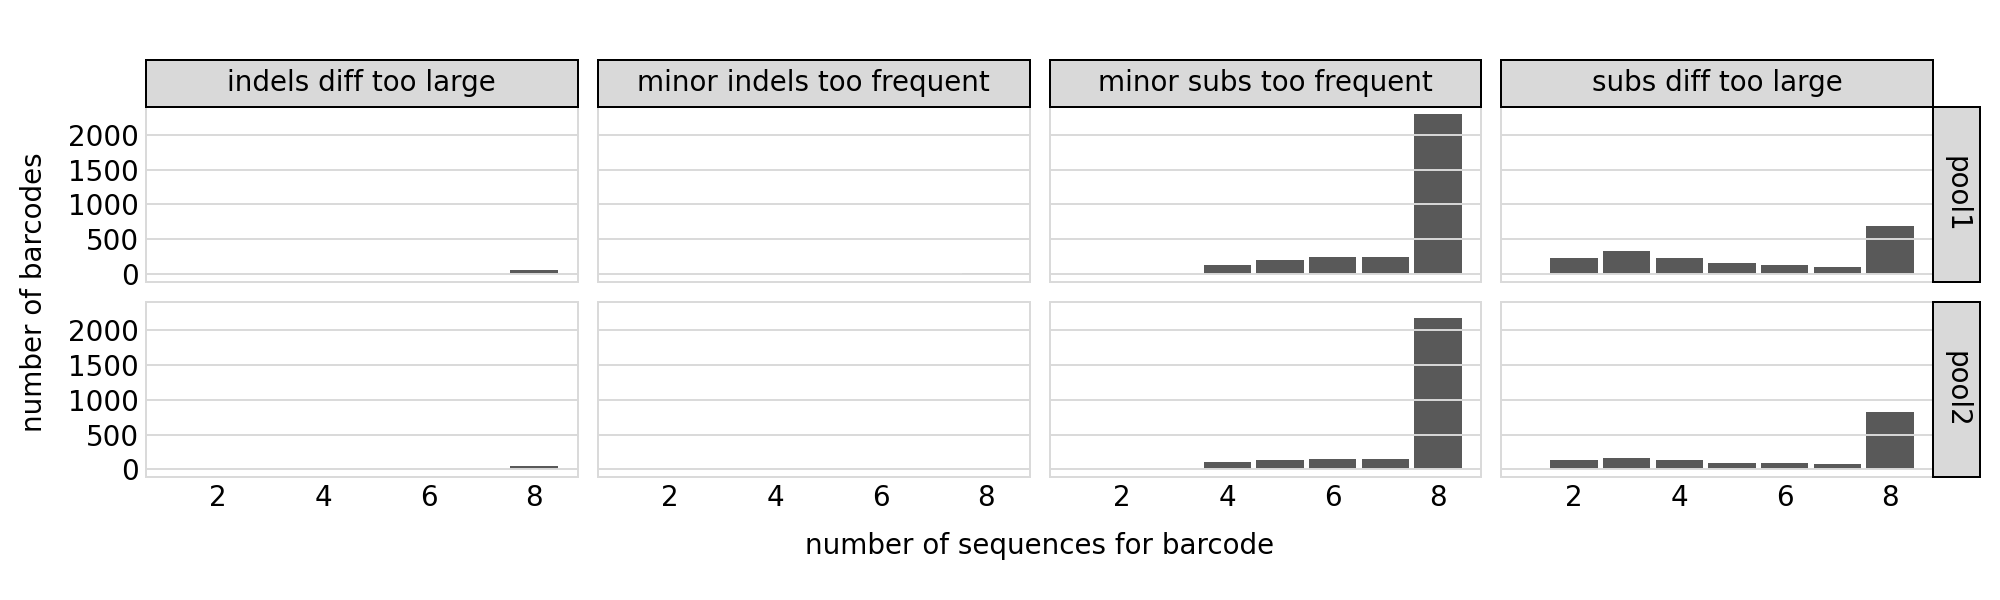

In [49]:
max_nseqs = 8  # plot together all barcodes with >= this many sequences

_ = (
 ggplot(
    dropped.assign(nseqs=lambda x: numpy.clip(x['nseqs'], None, max_nseqs)),
    aes('nseqs')) + 
 geom_bar() + 
 scale_x_continuous(limits=(1, None)) +
 xlab('number of sequences for barcode') +
 ylab('number of barcodes') +
 facet_grid('library ~ drop_reason') +
 theme(figure_size=(10, 1.5 * nlibs),
       panel_grid_major_x=element_blank(),
       )
 )
_.draw()

In [50]:
targets = alignparse.targets.Targets(seqsfile=config['amplicons_' + background],
                                     feature_parse_specs=config['feature_parse_specs_' + background])
geneseq = targets.get_target(background).get_feature('gene').seq

print(f"Read gene of {len(geneseq)} nts for {background} from {config['amplicons_' + background]}")

Read gene of 540 nts for aLIHA from data/PacBio_amplicon_aLIHA.gb


In [55]:
variants = dms_variants.codonvarianttable.CodonVariantTable(
                barcode_variant_file=config['nt_variant_table_file_' + background],
                geneseq=geneseq,
                primary_target=background,
                )

AttributeError: module 'dms_variants' has no attribute 'codonvarianttable'

In [57]:
dms_variants

<module 'dms_variants' from '/home/jhollis/miniconda3/lib/python3.8/site-packages/dms_variants/__init__.py'>

In [61]:
dms_variants.codonvarianttable()

AttributeError: module 'dms_variants' has no attribute 'codonvarianttable'

In [62]:
from dms_variants import codonvarianttable

In [63]:
codonvarianttable.CodonVariantTable()

TypeError: 'module' object is not callable

In [64]:
variants = codonvarianttable.CodonVariantTable(
                barcode_variant_file=config['nt_variant_table_file_' + background],
                geneseq=geneseq,
                primary_target=background,
                )

In [65]:
display(HTML(
    variants
    .n_variants_df(samples=None)
    .pivot_table(index=['target'],
                 columns='library',
                 values='count')
    .to_html()
    ))
     

library,pool1,pool2,all libraries
target,,,
aLIHA,76345,57489,133834


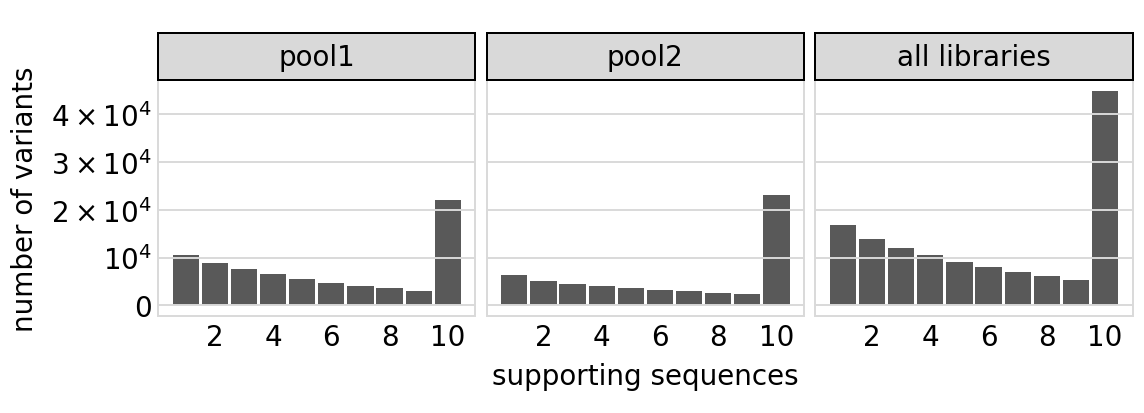

In [67]:
max_support = 10  # group variants with >= this much support

p = variants.plotVariantSupportHistogram(max_support=max_support,
                                         widthscale=1.1,
                                         heightscale=0.9)
p = p + theme(panel_grid_major_x=element_blank())  # no vertical grid lines
p.draw()

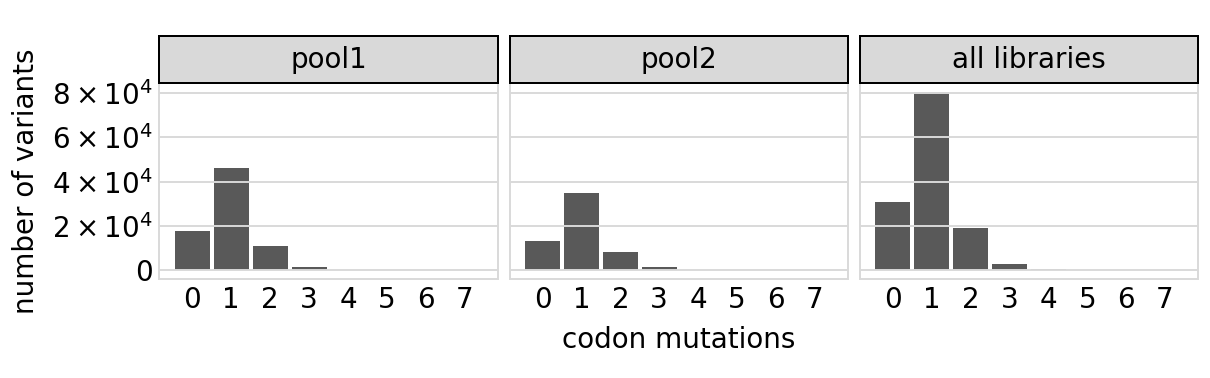

In [79]:
max_muts = 7  # group all variants with >= this many mutations

for mut_type in ['aa', 'codon']:
    p = variants.plotNumMutsHistogram(mut_type, samples=None, max_muts=max_muts,
                                      widthscale=1.1,
                                      heightscale=0.9)
    p = p + theme(panel_grid_major_x=element_blank())  # no vertical grid lines
p.draw()

In [80]:
p = variants.plotNumCodonMutsByType(variant_type='all', samples=None,
                                    ylabel='mutations per variant',
                                    heightscale=0.8)
p = p + theme(panel_grid_major_x=element_blank())  # no vertical grid lines
_ = p.draw()
plotfile = os.path.join(config['figs_dir'], f"avg_muts_per_variant_"+background+".pdf")
print(f"Saving plot to {plotfile}")
p.save(plotfile)

Saving plot to results/figures/avg_muts_per_variant_aLIHA.pdf


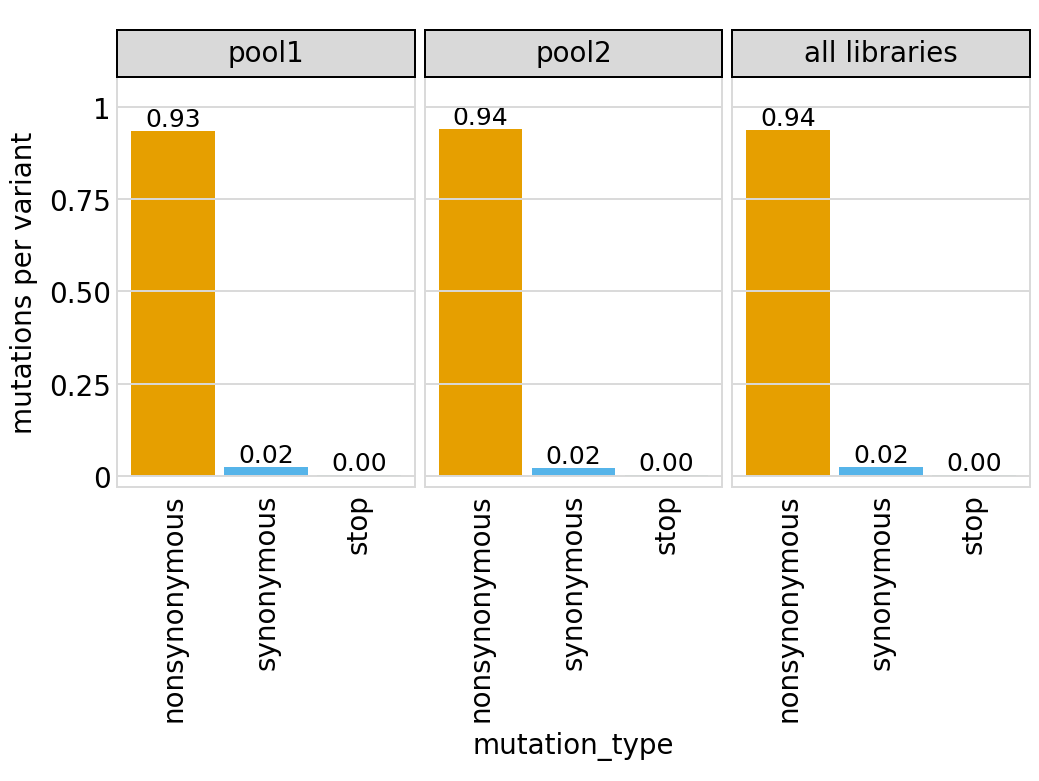

In [137]:
p = variants.plotNumCodonMutsByType(variant_type='all', samples=None,
                                    ylabel='mutations per variant',
                                    heightscale=1.7)
p = p + theme(panel_grid_major_x=element_blank())  # no vertical grid lines
p.draw()

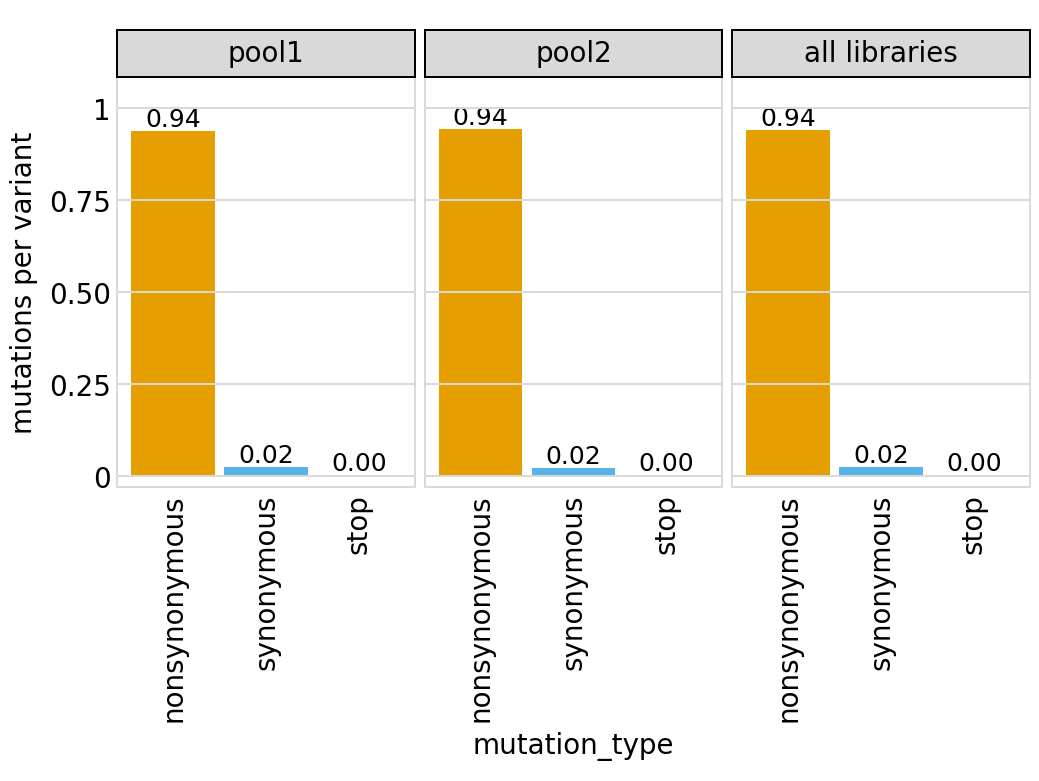

In [138]:
p = variants.plotNumCodonMutsByType(variant_type='all', samples=None,
                                    ylabel='mutations per variant', 
                                    min_support=2, heightscale=1.7)
p = p + theme(panel_grid_major_x=element_blank())  # no vertical grid lines
p.draw()

In [83]:
for variant_type in ['all', 'single']:
    p = variants.plotCumulMutCoverage(variant_type, mut_type='aa', samples=None)
    _ = p.draw()
    plotfile = os.path.join(config['figs_dir'],
                            f"variant_cumul_{variant_type}_mut_coverage_"+background+".pdf")
    print(f"Saving plot to {plotfile}")
    p.save(plotfile)

Saving plot to results/figures/variant_cumul_all_mut_coverage_aLIHA.pdf
Saving plot to results/figures/variant_cumul_single_mut_coverage_aLIHA.pdf


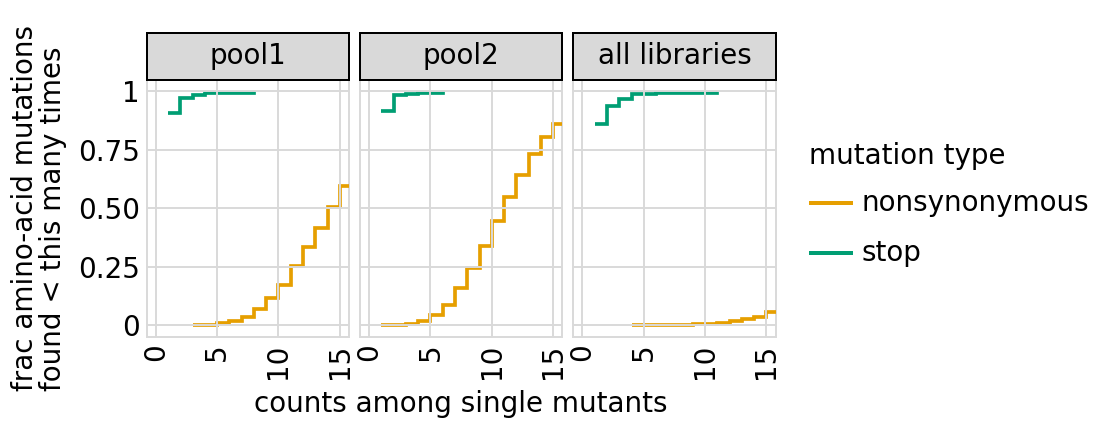

In [84]:
for variant_type in ['all', 'single']:
    p = variants.plotCumulMutCoverage(variant_type, mut_type='aa', samples=None)
p.draw()

In [85]:
count_dfs = []
for variant_type in ['all', 'single']:
    i_counts = (variants.mutCounts(variant_type, mut_type='aa', samples=None)
                .assign(variant_type=variant_type)
                )
    count_dfs += [i_counts.assign(include_stops=True),
                  i_counts
                  .query('not mutation.str.contains("\*")', engine='python')
                  .assign(include_stops=False)
                  ]
    
display(HTML(
    pd.concat(count_dfs)
    .assign(count=lambda x: (numpy.clip(x['count'], None, 2)
                             .map({0: '0', 1: '1', 2:'>1'}))
            )
    .groupby(['variant_type', 'include_stops', 'library', 'count'])
    .aggregate(number_of_mutations=pd.NamedAgg(column='mutation', aggfunc='count'))
    .to_html()
    ))

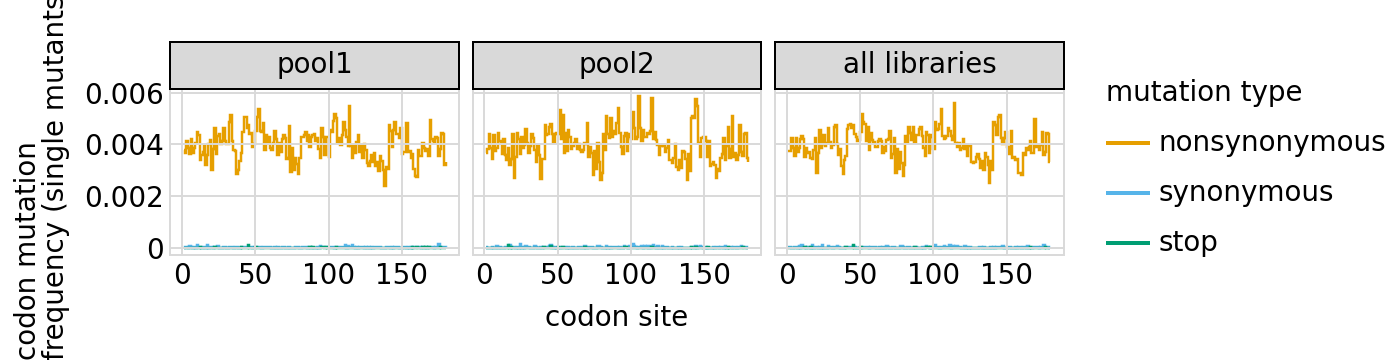

In [97]:
for variant_type in ['all', 'single']:
    p = variants.plotMutFreqs(variant_type, mut_type='codon', samples=None)
p.draw()

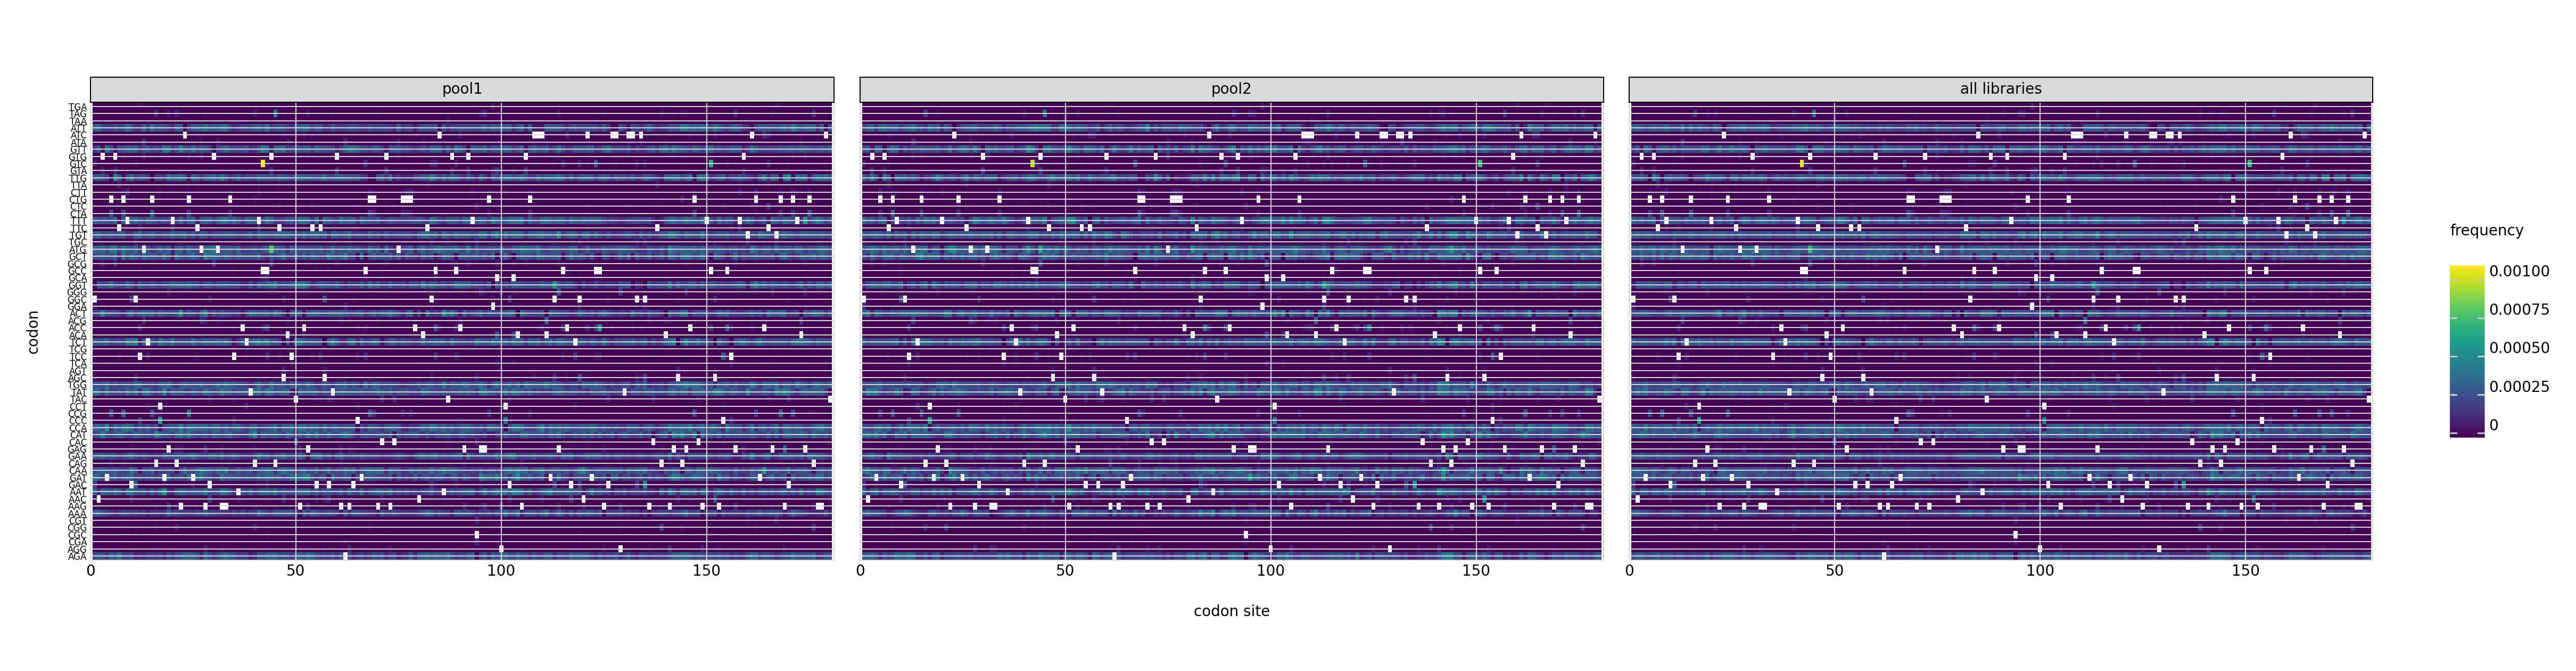

In [88]:
for mut_type in ['aa', 'codon']:
    p = variants.plotMutHeatmap('all', mut_type, samples=None, #libraries='all_only',
                                widthscale=2)
p.draw()

In [89]:
display(HTML(
    variants.barcode_variant_df
    .head()
    .to_html(index=False)
    ))

target,library,barcode,variant_call_support,codon_substitutions,aa_substitutions,n_codon_substitutions,n_aa_substitutions
aLIHA,pool1,AAAAAAAAAGAACTAG,25,AAG153TGT,K153C,1,1
aLIHA,pool1,AAAAAAAAGATCTAGG,8,CAC137CAA,H137Q,1,1
aLIHA,pool1,AAAAAAACCAACCCTT,33,ACC90ATT,T90I,1,1
aLIHA,pool1,AAAAAAACCCCAAAAT,11,GGC83ATT,G83I,1,1
aLIHA,pool1,AAAAAAAGCAGGACCC,5,ACA111TTG,T111L,1,1


In [90]:
print(f"Writing codon-variant table to {config['codon_variant_table_file_'+background]}")

variants.barcode_variant_df.to_csv(config['codon_variant_table_file_'+background], index=False)

Writing codon-variant table to results/variants/codon_variant_table_aLIHA.csv
